# Ablation Study: Hybrid CNN-GRU with Temporal Attention on FD002

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import (
    Input, Conv1D, BatchNormalization, Bidirectional, GRU,
    Dense, Dropout, Layer
)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import mean_absolute_error, mean_squared_error

np.random.seed(42)
tf.random.set_seed(42)

## 1. Load Preprocessed FD002 Data

In [2]:
data_dir = '../Dataset/Processed/FD002'
X_train = np.load(os.path.join(data_dir, 'x_train.npy'))
y_train = np.load(os.path.join(data_dir, 'y_train.npy'))
X_val   = np.load(os.path.join(data_dir, 'x_val.npy'))
y_val   = np.load(os.path.join(data_dir, 'y_val.npy'))
X_test  = np.load(os.path.join(data_dir, 'x_test.npy'))
y_test  = np.load(os.path.join(data_dir, 'y_test.npy'))

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_val shape:   {X_val.shape}   | y_val shape:   {y_val.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")


X_train shape: (36857, 30, 14) | y_train shape: (36857,)
X_val shape:   (9362, 30, 14)   | y_val shape:   (9362,)
X_test shape:  (259, 30, 14)  | y_test shape:  (259,)


## 2. Loss Function & Evaluation Metrics

In [3]:
def asymmetric_mse(y_true, y_pred, alpha_early=1.0, alpha_late=2.0):
    """
    Penalizes overprediction (late prediction) 2x more than underprediction (early inspection).
    """
    diff = y_pred - y_true
    weight = tf.where(diff < 0, alpha_early, alpha_late)
    return tf.reduce_mean(weight * tf.square(diff))

def nasa_score(y_true, y_pred):
    """
    NASA PHM08 asymmetric scoring function.
    """
    errors = np.asarray(y_pred).flatten() - np.asarray(y_true).flatten()
    scores = np.where(
        errors < 0,
        np.exp(-errors / 13.0) - 1.0,
        np.exp(errors / 10.0) - 1.0
    )
    return float(np.sum(scores))

## 3. Define the Temporal Attention Layer & Model Architecture

In [4]:
@tf.keras.utils.register_keras_serializable(package="CustomLayers")
class TemporalAttention(Layer):
    def __init__(self, **kwargs):
        super(TemporalAttention, self).__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(
            name="attention_weight",
            shape=(input_shape[-1], 1),
            initializer="glorot_uniform",
            trainable=True
        )
        self.b = self.add_weight(
            name="attention_bias",
            shape=(1,),
            initializer="zeros",
            trainable=True
        )
        super(TemporalAttention, self).build(input_shape)

    def call(self, x):
        # x: (batch_size, seq_len, hidden_dim)
        e = tf.tanh(tf.matmul(x, self.W) + self.b)  # (batch_size, seq_len, 1)
        a = tf.nn.softmax(e, axis=1)                # (batch_size, seq_len, 1)
        context = tf.reduce_sum(x * a, axis=1)      # (batch_size, hidden_dim)
        return context

    def get_config(self):
        config = super(TemporalAttention, self).get_config()
        return config

def build_hybrid_attention(input_shape=(30, 14)):
    inputs = Input(shape=input_shape, name="input_sensors")

    # CNN Feature Extractor (cross-sensor patterns)
    x = Conv1D(64, kernel_size=3, activation='relu', padding='same', name="conv1d_1")(inputs)
    x = BatchNormalization(name="bn_1")(x)
    x = Conv1D(32, kernel_size=3, activation='relu', padding='same', name="conv1d_2")(x)
    x = BatchNormalization(name="bn_2")(x)

    # Bidirectional GRU with return_sequences=True to feed all 30 cycles into Attention
    x = Bidirectional(GRU(32, return_sequences=True), name="bi_gru")(x)
    x = Dropout(0.3, name="drop_1")(x)

    # Temporal Attention Layer
    context = TemporalAttention(name="temporal_attention")(x)

    # Dense Regression Head
    x = Dense(32, activation='relu', name="dense_1")(context)
    x = Dropout(0.2, name="drop_2")(x)
    outputs = Dense(1, name="rul_output")(x)

    model = Model(inputs=inputs, outputs=outputs, name="Hybrid_CNN_GRU_Attention")
    return model

model_attn = build_hybrid_attention(input_shape=(30, 14))
model_attn.summary()


Model: "Hybrid_CNN_GRU_Attention"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_sensors (InputLayer)           │ (None, 30, 14)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 30, 64)              │           2,752 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn_1 (BatchNormalization)            │ (None, 30, 64)              │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                    │ (None, 30, 32)              │           6,176 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bn_2 (BatchNormalization)            │ (None, 30, 32)              │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bi_gru (Bidirectional)               │ (None, 30, 64)              │          12,672 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ drop_1 (Dropout)                     │ (None, 30, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ temporal_attention                   │ (None, 64)                  │              65 │
│ (TemporalAttention)                  │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ drop_2 (Dropout)                     │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rul_output (Dense)                   │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,162 (94.38 KB)

 Trainable params: 23,970 (93.63 KB)

 Non-trainable params: 192 (768.00 B)

## 4. Train the Model

In [5]:
model_attn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=asymmetric_mse,
    metrics=['mae']
)

os.makedirs('../Models/FD002', exist_ok=True)
checkpoint_path = '../Models/FD002/hybrid_cnn_gru_attention.keras'

callbacks = [
    EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6),
    ModelCheckpoint(checkpoint_path, monitor='val_loss', save_best_only=True)
]

start_time = time.time()
history_attn = model_attn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)
time_attn = time.time() - start_time
print(f"Training finished in {time_attn:.1f} seconds.")

Epoch 1/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - loss: 1811.5118 - mae: 29.5539 - val_loss: 543.6078 - val_mae: 16.6935 - learning_rate: 0.0010
Epoch 2/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - loss: 582.9914 - mae: 16.5360 - val_loss: 461.8584 - val_mae: 14.0585 - learning_rate: 0.0010
Epoch 3/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - loss: 473.6405 - mae: 14.6935 - val_loss: 400.5020 - val_mae: 12.3013 - learning_rate: 0.0010
Epoch 4/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - loss: 427.0554 - mae: 13.9011 - val_loss: 415.0018 - val_mae: 12.1856 - learning_rate: 0.0010
Epoch 5/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - loss: 401.7740 - mae: 13.4871 - val_loss: 428.5895 - val_mae: 13.7440 - learning_rate: 0.0010
Epoch 6/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - loss: 372.0114 - mae: 12.9729 - val_loss: 412.6967 - val_mae: 13.0430 - learning_rate: 0.0010
Epoch 7/100
576/576 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - loss: 346.1526 - mae: 12.5373 - val_loss: 

## 5. Save & Verify Model Checkpoint

In [6]:
# Save complete model
save_path = '../Models/FD002/hybrid_cnn_gru_attention.keras'
model_attn.save(save_path)

# Verify that model loads correctly with custom loss AND custom layer
loaded_model = tf.keras.models.load_model(
    save_path,
    custom_objects={
        'asymmetric_mse': asymmetric_mse,
        'TemporalAttention': TemporalAttention
    }
)
print("Successfully verified and loaded model from:", save_path)

Successfully verified and loaded model from: ../Models/FD002/hybrid_cnn_gru_attention.keras


## 6. Evaluation & Ablation Comparison (With vs. Without Attention)

In [7]:
# Predict on test set
y_pred_attn = model_attn.predict(X_test).flatten()
mae_attn = float(mean_absolute_error(y_test, y_pred_attn))
rmse_attn = float(np.sqrt(mean_squared_error(y_test, y_pred_attn)))
score_attn = float(nasa_score(y_test, y_pred_attn))

print(f"MAE:        {mae_attn:.2f} cycles")
print(f"RMSE:       {rmse_attn:.2f} cycles")
print(f"NASA Score: {score_attn:.1f}")

# Load baseline hybrid metrics for side-by-side ablation comparison
all_fd2 = pd.read_csv('../Results/comparison_tables/fd002_all_models_comparison.csv')
base_hybrid = all_fd2[all_fd2['Model'] == 'Hybrid CNN-GRU'].iloc[0]

ablation_table = pd.DataFrame([
    {
        'Model Architecture': 'Hybrid CNN-GRU (without Attention)',
        'MAE (Cycles)': base_hybrid['MAE'],
        'RMSE (Cycles)': base_hybrid['RMSE'],
        'NASA Score': base_hybrid['NASA Score'],
        'Description': 'Compresses 30 cycles via BiGRU (return_sequences=False)'
    },
    {
        'Model Architecture': 'Hybrid CNN-GRU + Attention (This Model)',
        'MAE (Cycles)': round(mae_attn, 2),
        'RMSE (Cycles)': round(rmse_attn, 2),
        'NASA Score': round(score_attn, 1),
        'Description': 'Dynamically weights all 30 cycles via Temporal Attention'
    }
])

print("\n=== ABLATION STUDY: IMPACT OF TEMPORAL ATTENTION ===")
print(ablation_table.to_string(index=False))

# Append attention model to fd002_all_models_comparison.csv so Notebook 05 receives it
os.makedirs('../Results/comparison_tables', exist_ok=True)
attn_row = pd.DataFrame([{
    'Model': 'Hybrid CNN-GRU + Attention',
    'MAE': round(mae_attn, 2),
    'RMSE': round(rmse_attn, 2),
    'NASA Score': round(score_attn, 1),
    'Training Time (s)': round(time_attn, 1)
}])

all_fd2_updated = all_fd2[all_fd2['Model'] != 'Hybrid CNN-GRU + Attention']
all_fd2_updated = pd.concat([all_fd2_updated, attn_row], ignore_index=True)
all_fd2_updated.to_csv('../Results/comparison_tables/fd002_all_models_comparison.csv', index=False)
print("\nUpdated fd002_all_models_comparison.csv with Attention Model metrics.")


9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step 
MAE:        12.01 cycles
RMSE:       16.71 cycles
NASA Score: 1350.4

=== ABLATION STUDY: IMPACT OF TEMPORAL ATTENTION ===
                     Model Architecture  MAE (Cycles)  RMSE (Cycles)  NASA Score                                              Description
     Hybrid CNN-GRU (without Attention)         12.95          17.03      1241.7  Compresses 30 cycles via BiGRU (return_sequences=False)
Hybrid CNN-GRU + Attention (This Model)         12.01          16.71      1350.4 Dynamically weights all 30 cycles via Temporal Attention

Updated fd002_all_models_comparison.csv with Attention Model metrics.


## 7. Attention Weights Visualization (Explainability / XAI)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step


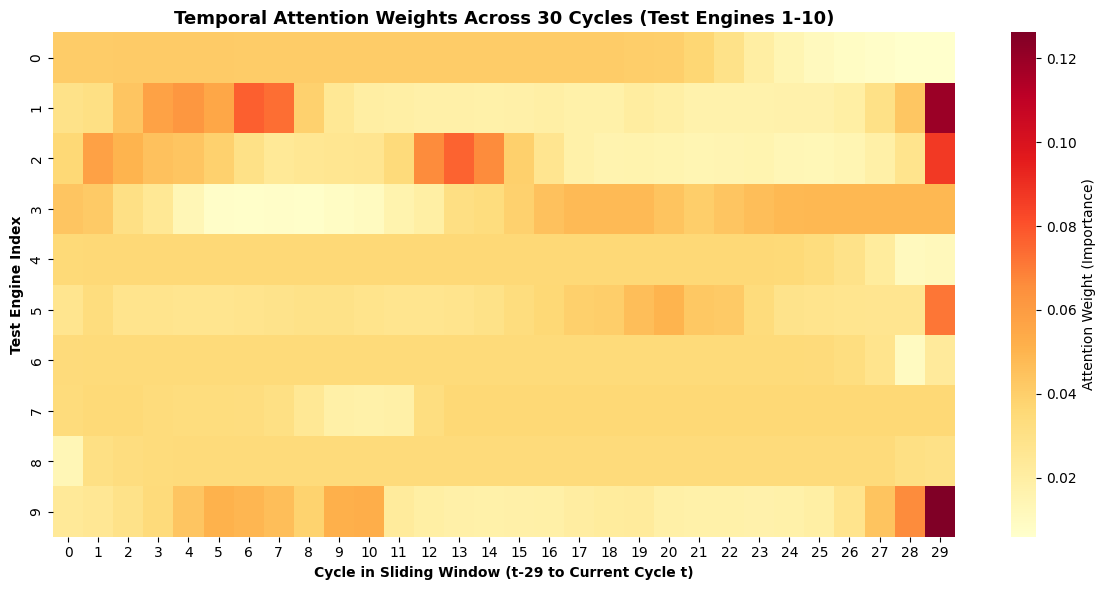

In [8]:
# Extract intermediate BiGRU outputs for the first 10 test engines
attn_submodel = Model(inputs=model_attn.input, outputs=model_attn.get_layer("bi_gru").output)
bi_gru_out = attn_submodel.predict(X_test[:10])

# Compute attention weights
attn_layer = model_attn.get_layer("temporal_attention")
W_val = attn_layer.weights[0].numpy()
b_val = attn_layer.weights[1].numpy()

e = np.tanh(np.matmul(bi_gru_out, W_val) + b_val)
e_exp = np.exp(e - np.max(e, axis=1, keepdims=True))
attn_weights = (e_exp / np.sum(e_exp, axis=1, keepdims=True)).squeeze(-1)  # shape: (10, 30)

# Heatmap across 10 engines
os.makedirs('../Results/plots', exist_ok=True)
plt.figure(figsize=(12, 6))
sns.heatmap(
    attn_weights,
    cmap="YlOrRd",
    annot=False,
    cbar_kws={'label': 'Attention Weight (Importance)'}
)
plt.title("Temporal Attention Weights Across 30 Cycles (Test Engines 1-10)", fontsize=13, fontweight='bold')
plt.xlabel("Cycle in Sliding Window (t-29 to Current Cycle t)", fontweight='bold')
plt.ylabel("Test Engine Index", fontweight='bold')
plt.tight_layout()
plt.savefig('../Results/plots/attention_weights_heatmap.png', dpi=200, bbox_inches='tight')
plt.show()
